# 10. Curriculum, konteks2048 dan profil RTX5070

Hasil aktual dari artefak pipeline. Data sintetis belum menjadi review manusia. Notebook ini tidak membuka target final dan tidak menjalankan training otomatis.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd().resolve()
while not (ROOT / '.venv').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'src/fullpage').is_dir(), 'Open using the project kernel and folder'
def read(path): return json.loads((ROOT / path).read_text(encoding='utf-8'))
display(Markdown('Environment proyek: ' + str(ROOT)))

Environment proyek: F:\Generative_AI\Vibe_Coding_Proyek_1

In [2]:
manifest = read('data/processed/fullpage/v1/manifest.json')
display({k:manifest[k] for k in ('family_counts','task_counts','block_size','output_budgets','max_prefix','max_target_with_eos','max_total_tokens','human_reviewed')})

{'family_counts': {'train': 240, 'validation': 40, 'test': 40},
 'task_counts': {'train': 5760, 'validation': 960, 'test': 800},
 'block_size': 2048,
 'output_budgets': {'page_plan': 512, 'section_content': 1536},
 'max_prefix': {'page_plan': 1404, 'section_content': 474},
 'max_target_with_eos': {'page_plan': 411, 'section_content': 349},
 'max_total_tokens': 1815,
 'human_reviewed': False}

## Panjang train/development

EOS tetap menjadi label. Prompt dan padding dimask. Nama/family berbeda antar split; komponen dan teks generik berulang secara sengaja.

count   min  median   max
split      task                                      
train      page_plan          960  1611  1722.0  1831
           section_content   4800   259   373.0   821
validation page_plan          160  1615  1724.5  1828
           section_content    800   260   388.5   839

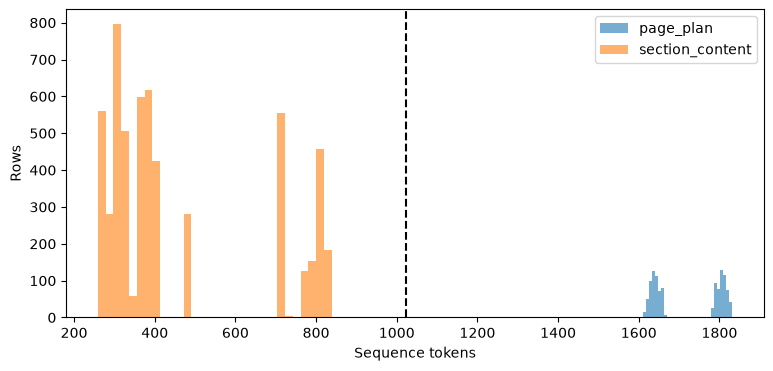

In [3]:
from src.data.normalize import read_jsonl
frames = []
for split in ('train','validation'):
    rows = list(read_jsonl(ROOT / f'data/processed/fullpage/v1/{split}.jsonl'))
    frames.append(pd.DataFrame(rows)[['task','length','genre','style_mode','retry']].assign(split=split))
lengths = pd.concat(frames)
display(lengths.groupby(['split','task']).length.agg(['count','min','median','max']))
fig, ax = plt.subplots(figsize=(9,4))
for task, group in lengths.groupby('task'):
    ax.hist(group.length, bins=30, alpha=.6, label=task)
ax.axvline(1024, color='black', linestyle='--'); ax.set(xlabel='Sequence tokens', ylabel='Rows'); ax.legend(); plt.show()

In [4]:
display(read('reports/data/FULLPAGE_LOADER_V1.json'))
row = next(read_jsonl(ROOT / 'data/processed/fullpage/v1/train.jsonl'))
print('Task:',row['task']); print('Prompt preview:',row['prompt'][:260]); print('Compact plan target:',row['target'])

{'kind': 'pipeline artifact diagnosis, not model generation',
 'manifest_sha256': '86f4b41126478f87018271cb655da062d00119176df978ad9b2886976535b348',
 'rows': {'train': 5760, 'validation': 960},
 'counts': {'train': {'landing_page:plain_css': 120,
   'landing_page:tailwind': 120,
   'company_profile:plain_css': 120,
   'company_profile:tailwind': 120},
  'validation': {'landing_page:plain_css': 20,
   'landing_page:tailwind': 20,
   'company_profile:plain_css': 20,
   'company_profile:tailwind': 20}},
 'families_disjoint': True,
 'intentional_target_duplicates': {'train': 3350, 'validation': 550},
 'shared_component_templates': True,
 'historical_final_used_for_selection': False,
 'final_targets_opened': False,
 'long_supervised_train_rows': 960,
 'prompt_labels_masked': 2484212,
 'eos_retained': True,
 'sampler_restored_exactly': True,
 'trim_shape': [3, 1818],
 'rejected_rows': 0,
 'pad_labels_masked': True}

Task: page_plan
Prompt preview: PLAN
{"asset_ids":["studio-shapes"],"business_facts":[{"id":"name","kind":"name","value":"Studio Mawikama"},{"id":"about","kind":"description","value":"Studio Mawikama adalah usaha demo fiktif di bidang desain dan komunikasi. Kami membantu pelanggan memahami p
Compact plan target: {"genre":"landing_page","language":"id","schema_version":"1.0","sections":[["nav","navbar","navigation","inline",["name"],[]],["main","hero","hero","split",["name"],["studio-shapes"]],["about","text_section","about","prose",["about"],[]],["services","feature_grid","services","cards",["srv0","srv1","srv2"],[]],["benefits","feature_grid","benefits","cards",["values"],[]],["process","feature_grid","process","numbered",["step0","step1","step2"],[]],["faq","feature_grid","faq","cards",["faq0","faq1","faq2"],[]],["contact","contact_form","contact","panel",[],[]],["footer","footer","footer","columns",["name"],[]]],"style_mode":"plain_css","theme":{"background":"#ffffff","font":"sans",

## Migrasi posisi

1.024 posisi lama identik, tambahan1.024 diinisialisasi dengan seed42. Bobot lama dipertahankan. Diagnosis logits pendek bukan bukti posisi baru sudah belajar.

In [5]:
display(read('reports/training/INIT-2048-001.json'))
display(read('reports/training/INIT-2048-001_LOAD_INSPECTION.json'))

{'status': 'completed',
 'initialization_kind': 'weights_only_position_extension',
 'source_checkpoint_sha256': '3399709ffe2fa7981c9d26b8ff5723f7821bd78e302bea6dfe63aaf1d27c8638',
 'checkpoint': 'checkpoints\\INIT-2048-001\\initial.pt',
 'checkpoint_sha256': '27a68c6a66bdb60fb9a729c9fd718e6eaa10d1b4d7e5f8789576339048ab9372',
 'model_config': {'vocab_size': 8192,
  'block_size': 2048,
  'n_layer': 6,
  'n_head': 6,
  'n_embd': 384,
  'dropout': 0.1,
  'tie_embeddings': True,
  'initialization': 'random normal mean 0 std 0.02; no pretrained weights'},
 'parameter_count': 14579712,
 'unchanged_tensors': ['token_embedding.weight',
  'position_embedding.weight',
  'blocks.0.attention_norm.weight',
  'blocks.0.attention_norm.bias',
  'blocks.0.attention.qkv.weight',
  'blocks.0.attention.qkv.bias',
  'blocks.0.attention.projection.weight',
  'blocks.0.attention.projection.bias',
  'blocks.0.mlp_norm.weight',
  'blocks.0.mlp_norm.bias',
  'blocks.0.mlp.0.weight',
  'blocks.0.mlp.0.bias',
  'b

{'status': 'initialization_load_and_lineage_checked',
 'checkpoint_sha256': '27a68c6a66bdb60fb9a729c9fd718e6eaa10d1b4d7e5f8789576339048ab9372',
 'mismatched_model_rejected': True,
 'state_has_optimizer': False,
 'positions': 2048,
 'new_positions_trained': False}

,batch,accumulation,status,tokens_per_second,peak_allocated_bytes,free_device_bytes
0,4,12,stable,43715.853738,1196771328,10205790208
1,8,6,stable,60524.755756,2038042112,9329180672
2,12,4,stable,63715.891263,2881448960,8383365120
3,16,3,stable,72030.218489,3723724288,7521435648


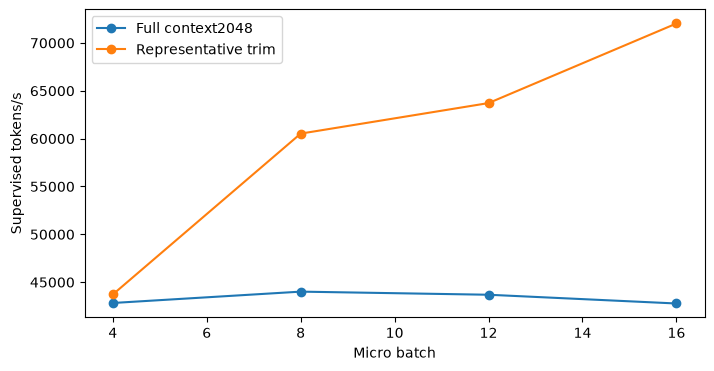

Selected: 16 accumulation: 3


In [6]:
profile = read('reports/training/FULLPAGE-GPU-002.json')
worst = read('reports/training/FULLPAGE-GPU-001.json')
display(pd.DataFrame([{k:r.get(k) for k in ('batch','accumulation','status','tokens_per_second','peak_allocated_bytes','free_device_bytes')} for r in profile['results']]))
fig, ax = plt.subplots(figsize=(8,4))
ax.plot([r['batch'] for r in worst['results']], [r.get('tokens_per_second',0) for r in worst['results']], 'o-', label='Full context2048')
ax.plot([r['batch'] for r in profile['results']], [r.get('tokens_per_second',0) for r in profile['results']], 'o-', label='Representative trim')
ax.set(xlabel='Micro batch',ylabel='Supervised tokens/s'); ax.legend(); plt.show()
print('Selected:',profile['selected']['batch'],'accumulation:',profile['selected']['accumulation'])

## Fixture renderer

Empat fixture manual9 bagian tersedia di examples/generated/AI-018-manual. Ini contoh kontrak dan ekspor, bukan raw model output. CSS responsif sudah tersedia; penerimaan browser390/1440 tetap pending.

In [7]:
fixture = read('reports/fullpage/AI-018_RENDER_FIXTURES.json')
display({k:v for k,v in fixture.items() if k!='fixtures'})
for page in fixture['fixtures']: print(page['genre'],page['style'],page['label'])

{'local_refs_and_fragments_valid': True,
 'fact_mismatch_rejected': True,
 'text_escaped': True,
 'asset_traversal_rejected': True,
 'legacy_renderer_unchanged_sha256': '03a6b2c6da832e82a3869c7b3db401535c0b1ceec23d0e646a379925b76f624c',
 'browser_status': 'pending',
 'viewports_planned': [390, 1440]}

landing_page plain_css manual curriculum fixture, not model output
landing_page tailwind manual curriculum fixture, not model output
company_profile plain_css manual curriculum fixture, not model output
company_profile tailwind manual curriculum fixture, not model output
